# Train a tiny resume parser on eight pages

This notebook trains a ResuVL-S model, the smallest of the three, on the six training pages in
`examples/`, then scores it on those pages and on two pages it has not seen. It runs the same code as the full
training, so every step of the pipeline can be watched and changed.

**Where to run it.** On Colab, choose *Runtime > Change runtime type > T4 GPU*; the whole notebook took 16 minutes
in a test run on a T4. On a local machine, install with
`pip install -e ".[notebook]"` and open the notebook from the repository; it uses a CUDA GPU or Apple MPS if one is
present and otherwise the CPU (the whole notebook took 8 minutes on an Apple M2 Max).

**What to expect.** Six pages teach the model the output format and let it memorise those pages; they do not teach
it to read new CVs. The full recipe in `docs/training.md` uses 1,393 pages.

Outputs go to `runs/example/` in the repository folder.

## 1. Setup

On Colab this clones the repository and installs the package (about 1 minute). Locally it only moves to the
repository root. `TINY_RESUME_PARSER_DATA` points the package at `examples/` and must be set before the package is
imported.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/tiny-resume-parser").exists():
        !git clone -q https://github.com/iamkucuk/tiny-resume-parser /content/tiny-resume-parser
    %cd /content/tiny-resume-parser
    %pip install -q -e .
elif Path.cwd().name == "examples":
    os.chdir("..")

os.environ["TINY_RESUME_PARSER_DATA"] = "examples"
sys.path.insert(0, "src")  # an editable install is only seen by a restarted kernel

MODEL = "ibm-granite/granite-docling-258M"
OUT = Path("runs/example")
# The ResuVL-S recipe (configs/resuvl-s.toml): lr 1e-4, 12 image tiles, image noise on half the
# pages. Different here: 15 epochs and one optimizer step per page (--accum 1), because there are only six pages.
EPOCHS = 15
print(f"working in {Path.cwd()}, outputs to {OUT}")

working in /Users/furkan/Documents/projects/cv_parser, outputs to runs/example


## 2. One page and its label

Each line of `examples/train.jsonl` holds a page image path and the record the teacher model wrote for it. The
student learns to write the compact form below: the record as JSON with empty fields left out.

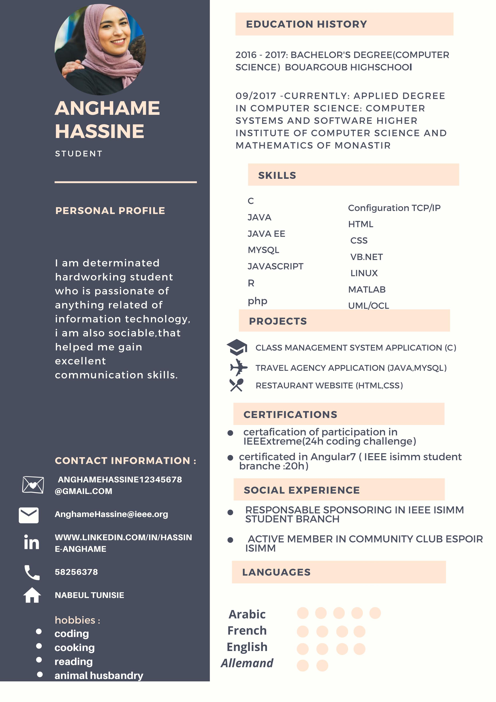

{"basics":{"name":"ANGHAME HASSINE","label":"STUDENT","emails":["ANGHAMEHASSINE12345678@GMAIL.COM","AnghameHassine@ieee.org"],"phones":["58256378"],"summary":"I am determined hardworking student who is passionate of anything related of information technology, i am also sociable,that helped me gain excellent communication skills","location":{"address":"NABEUL TUNISIE"},"profiles":[{"network":"LinkedIn","url":"WWW.LINKEDIN.COM/IN/HASSINE-ANGHAME"}],"hasPhoto":true},"volunteer":[{"organization":"IEEE ISIMM STUDENT BRANCH","position":"RESPONSABLE SPONSORING"},{"organization":"COMMUNITY CLUB ESPOIR ISIMM","position":"ACTIVE MEMBER"}],"education":[{"institution":"BOUARGOUB HIGHSCHOOL","area":"COMPUTER SCIENCE","studyType":"BACHELOR'S DEGREE","startDate":"2016","endDate":"2017"},{"institution":"HIGHER INSTITUTE OF COMPUTER SCIENCE AND MATHEMATICS OF MONASTIR","area":"COMPUTER SCIENCE: COMPUTER SYSTEMS AND SOFTWARE","studyType":"APPLIED DEGREE","startDate":"2017-09","endDate":"present"}],"cert

In [2]:
from tiny_resume_parser.data import page_image, read_jsonl
from tiny_resume_parser.models import student_target

train_rows = read_jsonl("examples/train.jsonl")
eval_rows = read_jsonl("examples/eval.jsonl")
row = train_rows[0]
display(page_image(row).resize((496, 702)))
target = student_target(row["record"])
print(target[:1000], "...")
print(f"{len(train_rows)} training pages, {len(eval_rows)} unseen pages; this target is {len(target)} characters")

## 3. Train

This runs `tiny-resume-parser train` in the notebook process so the progress bar shows here. Before the first step
it prints a mask check: the number of image tokens (none of them learnt) and of answer tokens (the only ones in the
loss). On a T4 the run uses float32 because the T4 has no bf16. The batch is already one page; if it runs out of
memory, restart the runtime and close other notebooks.

In [3]:
from tiny_resume_parser import train

args = f"--model {MODEL} --lr 1e-4 --max-patches 12 --augment 0.5 --epochs {EPOCHS} --accum 1 --logging-steps 5"
train.main(f"{args} --train-file examples/train.jsonl --out {OUT}".split())

train 6 pages, validation 0 pages (0 CVs)


mask check ok: 832 image tokens masked, 489 answer tokens learnt


full fine-tune: 257.5 M parameters, bf16 False


/Users/furkan/Documents/projects/cv_parser/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
5,1.469100
10,0.975800
15,0.684300
20,0.368200
25,0.262800
30,0.264400
35,0.187000
40,0.089700
45,0.098500
50,0.053000


0

## 4. Training loss

The loss is the mean cross-entropy over the answer tokens. On six pages it falls from about 1.5 to below 0.01: the model
has memorised them.

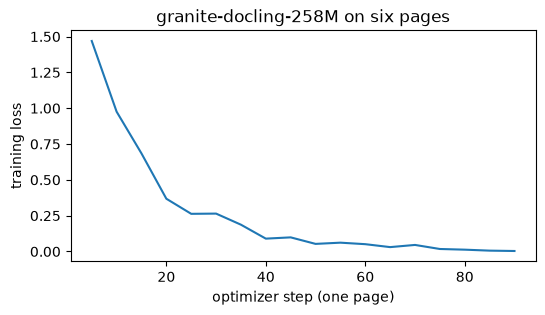

loss 1.47 at step 5, 0.003 at step 90


In [4]:
import json

import matplotlib.pyplot as plt

log = [e for e in json.loads((OUT / "log_history.json").read_text()) if "loss" in e]
plt.figure(figsize=(6, 3))
plt.plot([e["step"] for e in log], [e["loss"] for e in log])
plt.xlabel("optimizer step (one page)")
plt.ylabel("training loss")
plt.title("ResuVL-S on six pages")
plt.show()
print(f"loss {log[0]['loss']:.2f} at step {log[0]['step']}, {log[-1]['loss']:.3f} at step {log[-1]['step']}")

## 5. Score on seen and unseen pages

`evaluate` reads each page, compares the answer with the label field by field and writes one line per page to
`pages.jsonl` (docs/evaluation.md explains the score). In two test runs: field F1 0.78 and 1.00 on the six training pages,
0.16 and 0.01 on the two unseen pages. With six pages, the random image noise makes each run differ. A page takes 20 to 40 seconds on a T4 (float32; the T4 has no bf16) and 6
to 36 seconds on an Apple M2 Max; an answer that repeats itself runs to the 2,500-token limit and takes longest.

Loading the saved model prints a warning about an "incorrect regex pattern" in the tokenizer. It does not apply
here: the saved and the original tokenizer give identical token ids on all eight labels.

In [5]:
from tiny_resume_parser import evaluate

seen = evaluate.main(f"--model {OUT}/model --labels examples/train.jsonl --out {OUT}/eval_train".split())
unseen = evaluate.main(f"--model {OUT}/model --labels examples/eval.jsonl --out {OUT}/eval_unseen".split())
print(f"field F1 (strict): seen pages {seen['field_f1']:.2f}, unseen pages {unseen['field_f1']:.2f}")

The tokenizer you are loading from 'runs/example/model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


mps, examples/train.jsonl: 6 pages


  CV-ANGHAME-HASSINE p1: valid, F1 1.00, 488 tokens, 8 s/page


  CV-Trabelsi-Ahmed p1: valid, F1 0.89, 484 tokens, 9 s/page


  Ben_Hadj-Messaoud-Amine-56 p1: valid, F1 0.98, 440 tokens, 7 s/page


...

{"set": "examples/train.jsonl", "start": 0, "pages": 6, "model": "runs/example/model", "batch": 1, "max_patches": 12, "valid": 4, "schema_error": 1, "unparsed": 1, "hit_token_limit": 0, "field_precision": 0.939, "field_recall": 0.6611, "field_f1": 0.7759}


mps, examples/eval.jsonl: 2 pages


  Mohamed-CV-92 p1: schema_error, F1 0.24, 642 tokens, 10 s/page


  curriculumvitaetunisie32_png p1: unparsed, F1 0.00, 810 tokens, 13 s/page


{"set": "examples/eval.jsonl", "start": 0, "pages": 2, "model": "runs/example/model", "batch": 1, "max_patches": 12, "valid": 0, "schema_error": 1, "unparsed": 1, "hit_token_limit": 0, "field_precision": 0.2388, "field_recall": 0.126, "field_f1": 0.1649}
field F1 (strict): seen pages 0.78, unseen pages 0.16


## 6. Read an unseen answer

The answer below is for a page the model never saw. Its structure is right; the values show what six pages are not
enough for.

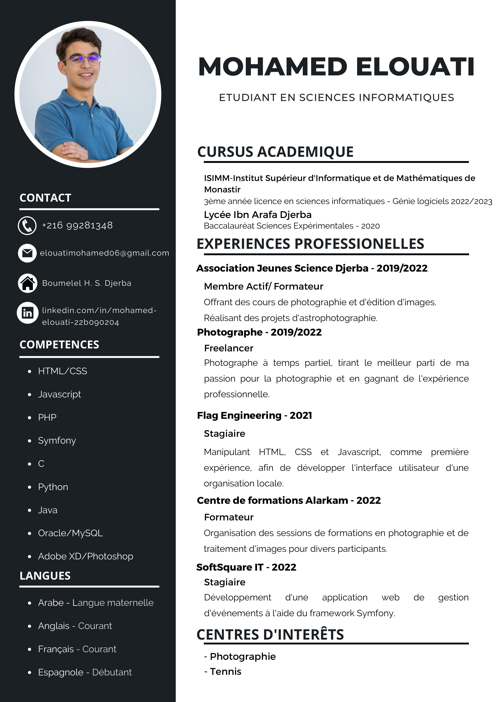

schema_error 
 {"basics":{"name":"MOHAME ETUARI","label":"COMPETENCES","emails":["éluatointedam06@gmail.com"],"phones":["+216 99281348"],"summary":"Lycée Ibn Arafa Djerba","location":{"address":"Boumelé, H. S. Djerba"},"profiles":[{"network":"LinkedIn","url":"linkedin.com/in/mohamed-elouati-22b090204"}],"hasPhoto":true},"work":[{"name":"ISIMM-Institut Supérieur d'Informatique et de Mathématiques de Monastir","position":"COMPETENCES","type":"internship","location":"Monastir","startDate":"2022-07","endDate":"2022-08","summary":"Journée scientiques de géologie","startDateIn":"2020","endDateIn":"2021"},{"name":"HTML/CSS","position":"COMPETENCES","type":"internship","location":"Magasin de l'expérience professionnelle","startDate":"2021-07","endDate":"2021-08","summary":"Flag Engineering","startDateIn":"2021","endDateIn":"2021","technologies":["HTML","CSS","JavaScript"]}],"volunteer":[{"organization":"Centre de formations Alain-Team","position":"Photographie","startDate":"2022-07","endDate":

In [6]:
page = json.loads((OUT / "eval_unseen" / "pages.jsonl").read_text().splitlines()[0])
display(page_image(eval_rows[0]).resize((496, 702)))
print(page["status"], "\n", page["answer"][:1500])

## 7. Repair the broken answers

An unparsed answer scores 0 even when its first fields are right. `rescore --repair` cuts a broken answer at the
point where the JSON breaks and keeps the complete values before it, as `tiny-resume-parser parse` does for real
use. Repair raises the unseen pages' score only a little, because most label values are never written. The full models in the README were
trained on 1,393 pages and score 0.63 to 0.75 lenient F1 on 204 test pages.

In [7]:
from tiny_resume_parser import rescore

rescore.main(f"--repair --labels examples/eval.jsonl {OUT}/eval_unseen".split())

runs/example/eval_unseen: strict F1 0.163 (P 0.232 R 0.126) | lenient F1 0.184 (P 0.261 R 0.142) | content F1 0.187 (P 0.310 R 0.134)


## 8. Explore one page

The explorer reads one page with the trained model and shows why it gets the score it gets. Pick an example page
(or upload a page image or PDF; the first page is read) and press **Read page**.

- **Fields**: every (field, value) pair of the answer next to the label's value. *match*: same letters and digits;
  *differs*: same field, but a letter or digit differs (highlighted); *extra*: not in the label; *missing*: in the
  label but left out. Field F1 is computed from exactly these pairs.
- **Scores**: strict, lenient and content F1 for this page, each with its rule.
- **JSON**: the answer after repair, as `tiny-resume-parser parse` returns it.
- **Model input**: the image tiles the model receives and how many tokens they become.

It starts on the first unseen page. Each read takes 20 to 40 seconds on a T4.

In [8]:
sys.path.insert(0, "examples")
from explorer import Explorer, report

explorer = Explorer(OUT / "model", train_rows, eval_rows)
explorer.show()

The tokenizer you are loading from 'runs/example/model' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Widgets do not render in a saved copy of a notebook (for example on GitHub). The next cell prints the scores and the
field table of the page shown above as plain HTML, so a saved copy still shows them.

In [9]:
report(explorer)

,field,model,label
differs,basics.name,MOHAME ETUARI,MOHAMED ELOUATI
extra,basics.label,COMPETENCES,
missing,basics.label,,ETUDIANT EN SCIENCES INFORMATIQUES
differs,basics.emails,éluatointedam06@gmail.com,elouatimohamed06@gmail.com
match,basics.phones,+216 99281348,+216 99281348
differs,basics.location.address,"Boumelé, H. S. Djerba",Boumelel H. S. Djerba
match,basics.profiles.network,LinkedIn,LinkedIn
match,basics.profiles.url,linkedin.com/in/mohamed-elouati-22b090204,linkedin.com/in/mohamed-elouati-22b090204
match,basics.hasPhoto,True,True
extra,work.name,ISIMM-Institut Supérieur d'Informatique et de Mathématiques de Monastir,


## 9. Release the GPU (Colab)

Colab GPU time is limited; this ends the session. Copy anything from `runs/example/` first.

In [10]:
if "google.colab" in sys.modules:
    from google.colab import runtime

    runtime.unassign()